# Robust Regression: GAD-7 vs Memory (Day 2 Success)
This notebook runs a robust Bayesian regression (using Student-T likelihood) to test whether GAD-7 scores predict Day 2 choice success for Win and Lose domains.


In [1]:
import os
os.environ["JAX_PLATFORMS"] = "cpu"

import pandas as pd
import numpy as np
import pymc as pm
import arviz as az
import matplotlib.pyplot as plt
import seaborn as sns
from scipy import stats
import warnings

warnings.filterwarnings('ignore')


In [2]:
# Load Data
file_path = '../data/allsubs_combined.csv'
df = pd.read_csv(file_path)

# Extract subject-level data
sub_df = df.groupby('Sub').first().reset_index()

# Filter out missing data
sub_df = sub_df.dropna(subset=['GAD7', 'Day2_Win_Success', 'Day2_Lose_Success'])

x_raw = sub_df['GAD7'].values
y_win = sub_df['Day2_Win_Success'].values
y_lose = sub_df['Day2_Lose_Success'].values

# Standardize GAD7 to help the sampler
x = (x_raw - np.mean(x_raw)) / np.std(x_raw)

print(f"Running regression on {len(x)} subjects.")


Running regression on 67 subjects.


In [3]:
def run_robust_regression(x, y, name):
    with pm.Model() as RR:
        # Use bounded scale and nu > 2 to avoid ceiling point-mass collapse at y = 1.0
        a = pm.Normal('intercept', mu=np.mean(y), sigma=0.5)
        b = pm.Normal('slope', mu=0, sigma=0.5)
        eps = pm.TruncatedNormal('eps', mu=np.std(y), sigma=0.5, lower=0.05)
        
        y_hat = a + b * x
        nu_raw = pm.Gamma("nu_raw", alpha=2, beta=0.1)
        nu = pm.Deterministic("nu", nu_raw + 2.0)
        
        likelihood = pm.StudentT("likelihood", mu=y_hat, sigma=eps, nu=nu, observed=y)
        
        trace_robust = pm.sample(nuts_sampler="numpyro", draws=2000, tune=2000, chains=4, progressbar=False)
        
    return trace_robust, RR

print("Running Robust Regression for Win Memory...")
trace_win, model_win = run_robust_regression(x, y_win, "Win")

print("Running Robust Regression for Lose Memory...")
trace_lose, model_lose = run_robust_regression(x, y_lose, "Lose")

# Run Standard Pearson Regression
r_win, p_win = stats.pearsonr(x_raw, y_win)
r_lose, p_lose = stats.pearsonr(x_raw, y_lose)



Running Robust Regression for Win Memory...


Running Robust Regression for Lose Memory...


STANDARD PEARSON CORRELATION
GAD7 -> Win Memory:  r = -0.168, p = 0.1730
GAD7 -> Lose Memory: r = 0.083, p = 0.5065

ROBUST REGRESSION RESULTS (89% HDI)
GAD7 -> Win Memory HDI 89%: [-0.087, 0.014] -> INCLUDES 0
GAD7 -> Lose Memory HDI 89%: [-0.031, 0.072] -> INCLUDES 0



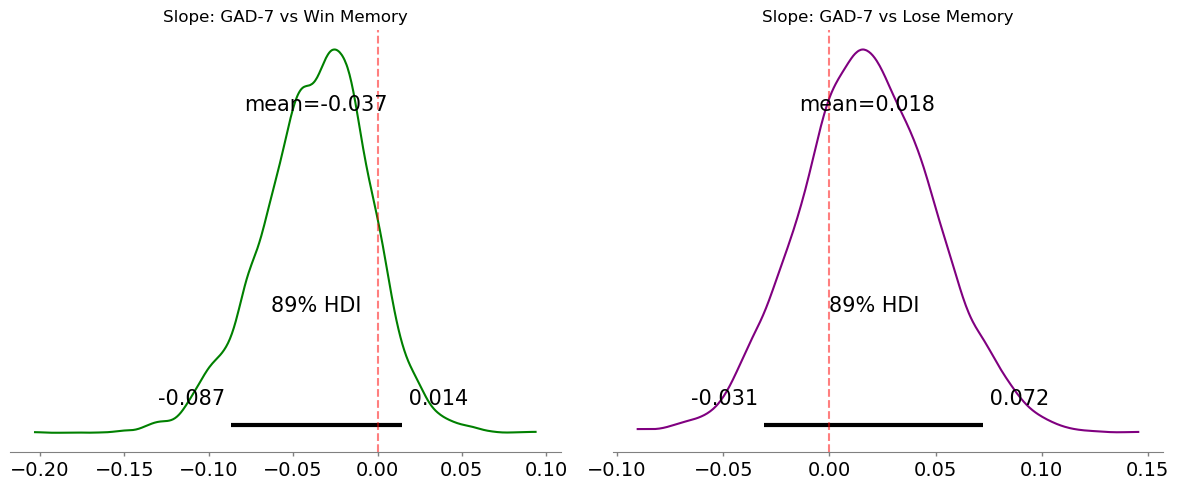

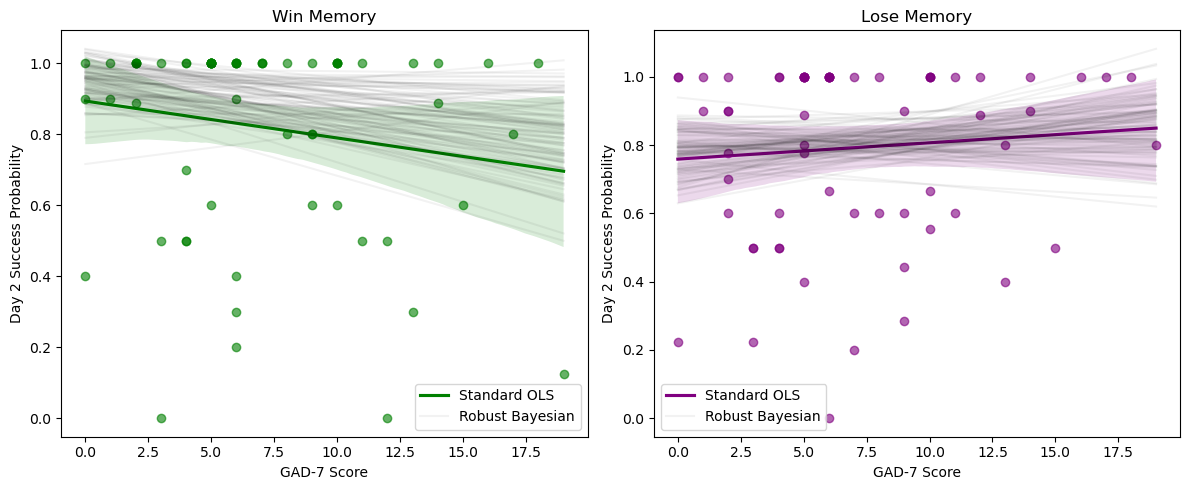

In [4]:
# Extract slopes
slope_win_samples = trace_win.posterior['slope'].values.flatten()
slope_lose_samples = trace_lose.posterior['slope'].values.flatten()

# Calculate 89% HDI
hdi_win = az.hdi(slope_win_samples, hdi_prob=0.89)
hdi_lose = az.hdi(slope_lose_samples, hdi_prob=0.89)

def check_significance(hdi, slope_name):
    includes_zero = hdi[0] <= 0 <= hdi[1]
    status = "INCLUDES 0" if includes_zero else "EXCLUDES 0"
    print(f"{slope_name} HDI 89%: [{hdi[0]:.3f}, {hdi[1]:.3f}] -> {status}")

print("==================================================")
print("STANDARD PEARSON CORRELATION")
print("==================================================")
print(f"GAD7 -> Win Memory:  r = {r_win:.3f}, p = {p_win:.4f}")
print(f"GAD7 -> Lose Memory: r = {r_lose:.3f}, p = {p_lose:.4f}")
print("\n==================================================")
print("ROBUST REGRESSION RESULTS (89% HDI)")
print("==================================================")
check_significance(hdi_win, "GAD7 -> Win Memory")
check_significance(hdi_lose, "GAD7 -> Lose Memory")
print("==================================================\n")

fig, axes = plt.subplots(1, 2, figsize=(12, 5))

az.plot_posterior(trace_win.posterior, var_names=['slope'], hdi_prob=0.89, ax=axes[0], color="green")
axes[0].set_title("Slope: GAD-7 vs Win Memory")
axes[0].axvline(0, color='red', linestyle='--', alpha=0.5)

az.plot_posterior(trace_lose.posterior, var_names=['slope'], hdi_prob=0.89, ax=axes[1], color="purple")
axes[1].set_title("Slope: GAD-7 vs Lose Memory")
axes[1].axvline(0, color='red', linestyle='--', alpha=0.5)

plt.tight_layout()
plt.show()

# Plot the regression lines
fig, axes = plt.subplots(1, 2, figsize=(12, 5))

for i, (y, trace, title, color) in enumerate(zip([y_win, y_lose], [trace_win, trace_lose], ["Win Memory", "Lose Memory"], ["green", "purple"])):
    ax = axes[i]
    
    # Plot standard OLS trend line and scatter points
    sns.regplot(x=x_raw, y=y, ax=ax, color=color, scatter_kws={'alpha': 0.6}, line_kws={'label': 'Standard OLS'})
    
    # Plot 100 posterior draws from the Robust Regression
    a_samples = trace.posterior['intercept'].values.flatten()
    b_samples = trace.posterior['slope'].values.flatten()
    
    idx = np.random.choice(len(a_samples), 100, replace=False)
    
    x_range_raw = np.linspace(min(x_raw), max(x_raw), 100)
    x_range_std = (x_range_raw - np.mean(x_raw)) / np.std(x_raw)
    
    for a, b in zip(a_samples[idx], b_samples[idx]):
        y_hat = a + b * x_range_std
        # Only add the label to the first line to avoid legend clutter
        label = 'Robust Bayesian' if a == a_samples[idx][0] else None
        ax.plot(x_range_raw, y_hat, color='black', alpha=0.05, label=label)
        
    ax.set_title(title)
    ax.set_xlabel("GAD-7 Score")
    ax.set_ylabel("Day 2 Success Probability")
    
    # Clean up the legend to only show the two lines
    handles, labels = ax.get_legend_handles_labels()
    by_label = dict(zip(labels, handles))
    ax.legend(by_label.values(), by_label.keys())

plt.tight_layout()
plt.show()
